# Cellrank

In [1]:
## Global variables

import os
import sys
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt
from copy import deepcopy
from scipy.stats import median_abs_deviation
from scipy import stats
from matplotlib.cm import get_cmap
import random

from scipy import io
import anndata as ad
import re
import palantir 
import scvi




/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvi/_settings.py:63: UserWarning: Since v1.0.0, scvi-tools no longer uses a random seed by default. Run `scvi.settings.seed = 0` to reproduce results from previous versions.
  self.seed = seed
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvi/_settings.py:70: UserWarning: Setting `dl_pin_memory_gpu_training` is deprecated in v1.0 and will be removed in v1.1. Please pass in `pin_memory` to the data loaders instead.
  self.dl_pin_memory_gpu_training = (


In [2]:
%matplotlib inline

plt.rcParams['figure.dpi'] = 100



In [3]:
save_dir='/sas/sara/scRNAseq/pendas/'
adata = sc.read_h5ad(save_dir+"adata_reannotated4.h5ad")

In [4]:
for x in adata.obs["manually_annotation"].unique():
    print(x)

MI
lP2
D
lP1
eP2
MII
mP
Sertoli
Leydig
eP1
SSCs
Spermatogonia
Fibroblasts
PTM
Endothelial
Macrophages
S2
S5
S3
S4
S7
S8
S1
S6
S10
S11


In [5]:
remap_leiden={
"SSCs":"Spermato",
"MI":"Spermato",
"lP2":"Spermato",
"D":"Spermato",
"lP1":"Spermato",
"eP2":"Spermato",
"mP":"Spermato",
"Sertoli":"Support",
"MII":"Spermato",
"Leydig":"Support",
"eP1":"Spermato",
"Spermatogonia":"Spermato",
"Endothelial_cells":"Spermato",
"PTM":"Support",
"Macrophagues":"Support",
"Endothelial":"Support",
"S5":"Spermato",
"S4":"Spermato",
"S7":"Spermato",
"S1":"Spermato",
"S2":"Spermato",
"S6":"Spermato",
"S10":"Spermato",
"S8":"Spermato",
"S9":"Spermato",
"S3":"Spermato",
"S11":"Spermato"}

adata.obs["manually_level1"] = adata.obs["manually_annotation"]
adata.obs["manually_level1"]  = adata.obs["manually_level1"].map(remap_leiden).astype('category')
adata.obs

,Sample,Group,n_genes,n_counts,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_rb,pct_counts_rb,...,manually_annotation,leiden_S_0.1,leiden_S_0.2,leiden_S_0.4,leiden_S_0.6,leiden_S_0.8,leiden_S_1,leiden_S_1.2,leiden_S_1.4,manually_level1
ACACGCGCATAGAGGC-1-0-0,SI-TT-A1,SIX6_D_Cterm,7075.0,88695.0,7064.0,88695,1746.0,1.968544,6467.0,7.291279,...,MI,10,10,10,10,10,10,10,10,Spermato
TGGGAGACAGTTGGTT-1-0-0,SI-TT-A1,SIX6_D_Cterm,6812.0,70090.0,6807.0,70090,1430.0,2.040234,5066.0,7.227850,...,MI,10,10,10,10,10,10,10,10,Spermato
CACACAACATGGAGAC-1-0-0,SI-TT-A1,SIX6_D_Cterm,6892.0,68932.0,6885.0,68932,2420.0,3.510706,6916.0,10.033076,...,lP2,4,4,4,4,4,4,4,4,Spermato
GAAATGAAGCCTCCAG-1-0-0,SI-TT-A1,SIX6_D_Cterm,6416.0,58599.0,6410.0,58599,1323.0,2.257718,4214.0,7.191249,...,D,10,10,10,10,10,10,10,10,Spermato
TGATTCTAGCCTCTTC-1-0-0,SI-TT-A1,SIX6_D_Cterm,6418.0,57103.0,6407.0,57103,1152.0,2.017407,4287.0,7.507486,...,D,10,10,10,10,10,10,10,10,Spermato
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ACATTTCTCGCCAGTG-1-4-0,SI-TT-H12,RNF212_KO,208.0,323.0,208.0,323,15.0,4.643963,159.0,49.226006,...,Spermatogonia,8,8,8,8,8,8,8,8,Spermato
GAAACCTCACCTGCAG-1-4-0,SI-TT-H12,RNF212_KO,288.0,373.0,288.0,373,8.0,2.144772,106.0,28.418231,...,Spermatogonia,8,8,8,8,8,8,8,8,Spermato
AAGTCGTAGGTGTGAC-1-4-0,SI-TT-H12,RNF212_KO,226.0,324.0,226.0,324,8.0,2.469136,90.0,27.777778,...,Fibroblasts,14,14,14,14,14,14,14,14,NaN
AGTAGTCTCTGGTCAA-1-4-0,SI-TT-H12,RNF212_KO,221.0,328.0,221.0,328,7.0,2.134146,152.0,46.341463,...,Spermatogonia,8,8,8,8,8,8,8,8,Spermato


In [6]:
reduced_adata = adata[adata.obs["manually_level1"]=="Spermato"]

In [7]:
reduced_adata

View of AnnData object with n_obs × n_vars = 21473 × 9531
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_

In [8]:
sc.pp.highly_variable_genes(reduced_adata,n_top_genes=5000,subset=True,batch_key="Sample")


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/preprocessing/_highly_variable_genes.py:539: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns['hvg'] = {'flavor': flavor}


In [9]:
legend_info={'D': '#d60000', 'MI': '#05acc6', 'MII': '#97ff00', 'S1': '#79525e', 'S2': '#00fdcf', 'S3': '#afa5ff', 'S4': '#93ac83', 'S5': '#9a6900', 'S6': '#366962', 'S7': '#d3008c', 'S8': '#fdf490', 'S9': '#c86e66', 'S10': '#9ee2ff', 'S11': '#00c846', 'SSCs': '#a877ac', 'Spermatogonia': '#f4bfb1', 'eP1': '#ff28fd', 'eP2': '#f2cdff', 'lP1': '#009e7c', 'lP2': '#ff6200', 'mP': '#56642a'}


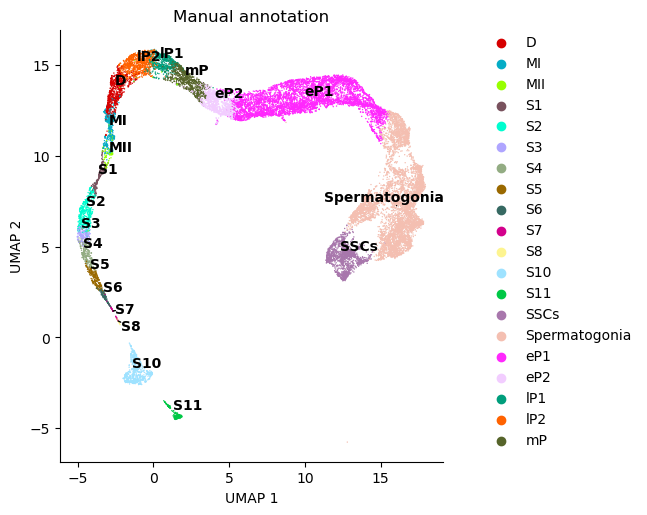

In [10]:
from adjustText import adjust_text

#adata_full.obs_names_make_unique()

def gen_mpl_labels(
    adata, groupby, exclude=(), ax=None, adjust_kwargs=None, text_kwargs=None
):
    if adjust_kwargs is None:
        adjust_kwargs = {"text_from_points": False, "force_text":10}
    if text_kwargs is None:
        text_kwargs = {}

    medians = {}

    for g, g_idx in adata.obs.groupby(groupby).groups.items():
        if g in exclude:
            continue
        medians[g] = np.median(adata[g_idx].obsm["X_umap"], axis=0)

    if ax is None:
        texts = [
            plt.text(x=x, y=y, s=k, **text_kwargs) for k, (x, y) in medians.items()
        ]
    else:
        texts = [ax.text(x=x, y=y, s=k, **text_kwargs) for k, (x, y) in medians.items()]

    adjust_text(texts, **adjust_kwargs)

with plt.rc_context({"figure.figsize": (6.5, 5), "figure.dpi": 100, "figure.frameon": False}):
    #ax = sc.pl.umap(adata_full, color="C_scANVI", show=False, legend_loc=None, frameon=False)
    plot = sns.scatterplot(x=reduced_adata.obsm["X_umap"][:,0], y=reduced_adata.obsm["X_umap"][:,1],hue =reduced_adata.obs["manually_annotation"],palette= legend_info,marker='.',s=4,linewidth=0)
    sns.despine()
    legend = plt.legend(bbox_to_anchor=(1.1, 1), loc=2, borderaxespad=0., frameon=False,fontsize=10)
    gen_mpl_labels(
        reduced_adata,
        "manually_annotation",
        exclude=("None",),  # This was before we had the `nan` behaviour
        ax=plot,
        adjust_kwargs=dict(arrowprops=dict(arrowstyle='-', color='black')),
        text_kwargs=dict(fontsize=10,weight='bold'),
    )
    fig = plot.get_figure()
    fig.tight_layout()
    plt.xlabel('UMAP 1')
    plt.ylabel('UMAP 2');
    plt.title("Manual annotation" )
    plt.show()

In [11]:
sc.pp.neighbors(reduced_adata, use_rep="X_scVI",key_added="neighbors_model")
sc.tl.umap(reduced_adata, min_dist=0.2,neighbors_key="neighbors_model")

2025-11-28 10:09:08.058027: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-11-28 10:09:08.058113: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-11-28 10:09:08.058191: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-11-28 10:09:13.759392: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [12]:
# Get colors and matching categories
palette = reduced_adata.uns["manually_annotation_colors"]
categories = reduced_adata.obs["manually_annotation"].cat.categories

# Make sure colors match the order of categories
# (only needed if you want to be explicit)
palette_dict = dict(zip(categories, palette))
palette_dict

{'D': '#d60000',
 'MI': '#97ff00',
 'MII': '#ffa52f',
 'S1': '#00fdcf',
 'S2': '#afa5ff',
 'S3': '#93ac83',
 'S4': '#9a6900',
 'S5': '#366962',
 'S6': '#d3008c',
 'S7': '#fdf490',
 'S8': '#c86e66',
 'S10': '#9ee2ff',
 'S11': '#00c846',
 'SSCs': '#a877ac',
 'Spermatogonia': '#f4bfb1',
 'eP1': '#ff28fd',
 'eP2': '#f2cdff',
 'lP1': '#009e7c',
 'lP2': '#ff6200',
 'mP': '#56642a'}

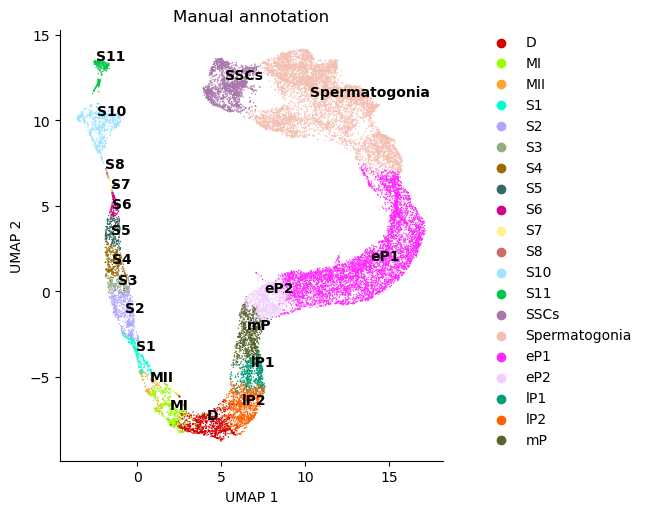

In [13]:
from adjustText import adjust_text

#adata_full.obs_names_make_unique()

def gen_mpl_labels(
    adata, groupby, exclude=(), ax=None, adjust_kwargs=None, text_kwargs=None
):
    if adjust_kwargs is None:
        adjust_kwargs = {"text_from_points": False, "force_text":10}
    if text_kwargs is None:
        text_kwargs = {}

    medians = {}

    for g, g_idx in adata.obs.groupby(groupby).groups.items():
        if g in exclude:
            continue
        medians[g] = np.median(adata[g_idx].obsm["X_umap"], axis=0)

    if ax is None:
        texts = [
            plt.text(x=x, y=y, s=k, **text_kwargs) for k, (x, y) in medians.items()
        ]
    else:
        texts = [ax.text(x=x, y=y, s=k, **text_kwargs) for k, (x, y) in medians.items()]

    adjust_text(texts, **adjust_kwargs)

with plt.rc_context({"figure.figsize": (6.5, 5), "figure.dpi": 100, "figure.frameon": False}):
    #ax = sc.pl.umap(adata_full, color="C_scANVI", show=False, legend_loc=None, frameon=False)
    plot = sns.scatterplot(x=reduced_adata.obsm["X_umap"][:,0], y=reduced_adata.obsm["X_umap"][:,1],hue =reduced_adata.obs["manually_annotation"],palette= palette_dict,marker='.',s=4,linewidth=0)
    sns.despine()
    legend = plt.legend(bbox_to_anchor=(1.1, 1), loc=2, borderaxespad=0., frameon=False,fontsize=10)
    gen_mpl_labels(
        reduced_adata,
        "manually_annotation",
        exclude=("None",),  # This was before we had the `nan` behaviour
        ax=plot,
        adjust_kwargs=dict(arrowprops=dict(arrowstyle='-', color='black')),
        text_kwargs=dict(fontsize=10,weight='bold'),
    )
    fig = plot.get_figure()
    fig.tight_layout()
    plt.xlabel('UMAP 1')
    plt.ylabel('UMAP 2');
    plt.title("Manual annotation" )
    plt.show()

### Pseudotime

In [14]:
# Diffusion maps 
import warnings
warnings.filterwarnings('ignore')
dm_res = palantir.utils.run_diffusion_maps(pd.DataFrame(reduced_adata.obsm['X_scVI'], index=reduced_adata.obs_names),n_components=10)
warnings.filterwarnings('default')
reduced_adata.obsp['DM_Kernel'] = dm_res['kernel']
reduced_adata.obsm['DM_EigenVectors'] = dm_res['EigenVectors'].values
reduced_adata.uns['DMEigenValues'] = dm_res['EigenValues'].values
reduced_adata

AnnData object with n_obs × n_vars = 21473 × 5000
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_1', 'l

In [15]:
palantir.utils.run_diffusion_maps(reduced_adata,n_components=10,pca_key="X_scVI")

{'T': <21473x21473 sparse matrix of type '<class 'numpy.float64'>'
 	with 863076 stored elements in Compressed Sparse Row format>,
 'EigenVectors':                                0         1         2         3         4  \
 ACACGCGCATAGAGGC-1-0-0 -0.006824 -0.003967 -0.012049 -0.001645  0.012455   
 TGGGAGACAGTTGGTT-1-0-0 -0.006824 -0.003958 -0.012038 -0.001661  0.012422   
 CACACAACATGGAGAC-1-0-0 -0.006824 -0.001655 -0.010628 -0.006621  0.009000   
 GAAATGAAGCCTCCAG-1-0-0 -0.006824 -0.003718 -0.011993 -0.002264  0.012490   
 TGATTCTAGCCTCTTC-1-0-0 -0.006824 -0.002866 -0.011647 -0.004296  0.011917   
 ...                          ...       ...       ...       ...       ...   
 AAGCATCTCTGACGCG-1-4-0 -0.006824  0.004061  0.004761  0.003854  0.004803   
 ACATTTCTCGCCAGTG-1-4-0 -0.006824  0.004058  0.004857  0.003984  0.005198   
 GAAACCTCACCTGCAG-1-4-0 -0.006824  0.004084  0.004584  0.003599  0.003873   
 AGTAGTCTCTGGTCAA-1-4-0 -0.006824  0.004074  0.004865  0.004015  0.005254   
 TTCCA

In [16]:
palantir.utils.determine_multiscale_space(reduced_adata,eigval_key="DM_EigenValues")


,0,1,2,3,4,5,6
ACACGCGCATAGAGGC-1-0-0,-11.137359,-12.681188,-0.846881,3.483086,-0.037409,-1.635606,0.488624
TGGGAGACAGTTGGTT-1-0-0,-11.112185,-12.669788,-0.854944,3.473997,-0.036565,-1.622912,0.488267
CACACAACATGGAGAC-1-0-0,-4.647037,-11.185369,-3.407966,2.516820,0.169676,0.516211,0.806746
GAAATGAAGCCTCCAG-1-0-0,-10.437189,-12.622299,-1.165395,3.493074,-0.011772,-1.464587,0.594335
TGATTCTAGCCTCTTC-1-0-0,-8.045471,-12.257945,-2.211616,3.332624,0.076902,-0.708299,0.859997
...,...,...,...,...,...,...,...
AAGCATCTCTGACGCG-1-4-0,11.399659,5.010573,1.984100,1.343206,0.051112,0.455286,-0.276552
ACATTTCTCGCCAGTG-1-4-0,11.391846,5.111956,2.050929,1.453652,0.052373,0.561258,-0.385697
GAAACCTCACCTGCAG-1-4-0,11.464403,4.824552,1.852549,1.083138,0.047199,0.189591,-0.021526
AGTAGTCTCTGGTCAA-1-4-0,11.437294,5.120089,2.066894,1.469237,0.056663,0.573814,-0.397401


In [17]:
reduced_adata.obsm['X_multiscale'] = reduced_adata.obsm["DM_EigenVectors_multiscaled"]

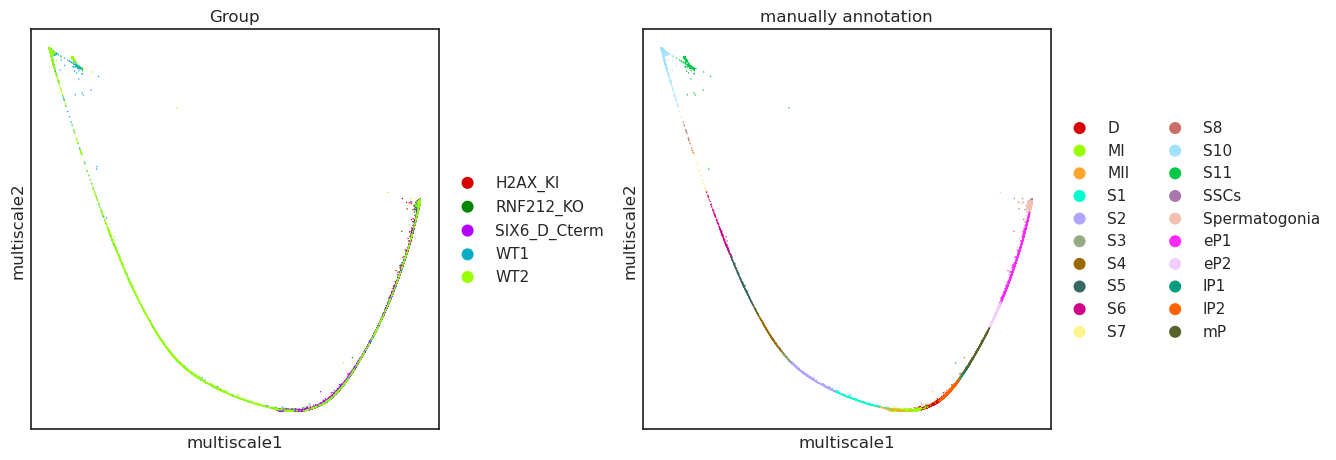

In [72]:
plt.rcParams["figure.figsize"] = [5,5]

sc.pl.scatter(reduced_adata, basis='multiscale', color=[ "Group",'manually_annotation'],size=4)

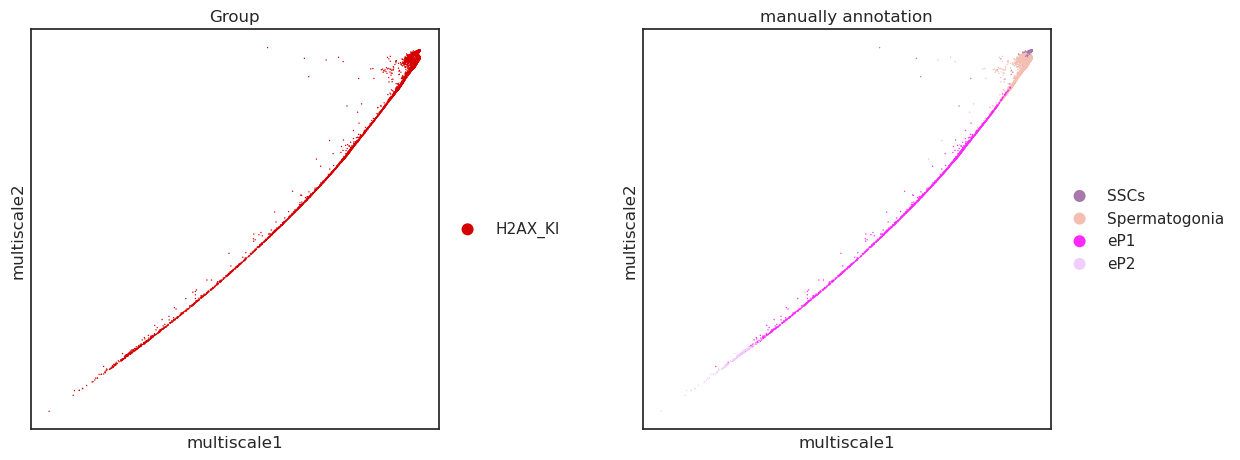

In [74]:
plt.rcParams["figure.figsize"] = [5,5]

sc.pl.scatter(reduced_adata[reduced_adata.obs["Group"].isin(["H2AX_KI"])], basis='multiscale', color=[ "Group",'manually_annotation'],size=4)

In [19]:
palantir.utils.run_magic_imputation(reduced_adata, expression_key="normalized_expression_log")

array([[0.19693373, 0.10185488, 0.44258505, ..., 0.09026421, 2.1206121 ,
        0.01800685],
       [0.20149678, 0.10947466, 0.45331237, ..., 0.0933204 , 2.0961404 ,
        0.02057529],
       [0.31772685, 0.11092087, 0.572531  , ..., 0.11317161, 3.1648474 ,
        0.02728684],
       ...,
       [0.        , 1.9617755 , 0.4299594 , ..., 0.04212176, 3.9885974 ,
        0.8543653 ],
       [0.        , 1.2524534 , 0.2547044 , ..., 0.04709034, 3.6590528 ,
        0.5929409 ],
       [0.        , 2.2829297 , 1.356671  , ..., 0.36431852, 4.1646185 ,
        0.07576399]], dtype=float32)

In [20]:
reduced_adata.obs_names[(reduced_adata.obs["manually_annotation"]=="SSCs") &(reduced_adata.obs["Group"]=="WT2")]

Index(['CCCTGATCAGTAGGAC-1-1-0', 'AGAGCCCTCCATCTCG-1-1-0',
       'GTAGCTATCACCCATC-1-1-0', 'GCTGCAGGTTCACCGG-1-1-0',
       'GGAGATGGTTTACTTC-1-1-0', 'ATGGAGGCACCGTCGA-1-1-0',
       'AGCGCTGAGGAAAGTG-1-1-0', 'ACACAGTTCATCTACT-1-1-0',
       'ACTACGAAGCCACTCG-1-1-0', 'TGACGCGGTATTGAGA-1-1-0',
       'TGTAGACAGGGCTAAC-1-1-0', 'ACATGCAGTTGGGTTT-1-1-0',
       'CCTCAACCAACACAGG-1-1-0', 'TGAGCATGTCGATTCA-1-1-0',
       'TGTAACGGTGGAGAAA-1-1-0', 'CCTCAACCAATTCTCT-1-1-0',
       'TTTACGTCACGCGGTT-1-1-0', 'GTCGAATGTTCGGTTA-1-1-0',
       'GTAGATCTCAAGCTGT-1-1-0', 'AGGGAGTTCACCTCTG-1-1-0',
       'CGGAGAAGTGACCTGC-1-1-0', 'CTACGGGGTTCTCCAC-1-1-0',
       'TCCGATCAGTCAGCGA-1-1-0', 'CACTGTCGTATTCTCT-1-1-0',
       'GCGGAAAGTGAGTTGG-1-1-0', 'TTTACCATCAAGTAAG-1-1-0',
       'GATCAGTAGCCTTCTC-1-1-0', 'GTGAGGAGTTGATCGT-1-1-0',
       'CTAACCCTCGCATGAT-1-1-0', 'AATTTCCGTAGTGTGG-1-1-0',
       'ATGGAGGCAAGAGAGA-1-1-0', 'GCAACATAGCTGACTT-1-1-0',
       'ATAGACCAGTGTCATC-1-1-0', 'TCATTTGTCTAGCAAC-1-1-0

In [21]:
reduced_adata.obs_names[(reduced_adata.obs["manually_annotation"]=="S11") &(reduced_adata.obs["Group"]=="WT2")]

Index(['CGCCATTCACTTCCTG-1-1-0', 'TTCACCGAGACCAGCA-1-1-0',
       'CATCCACCACTCCGGA-1-1-0', 'AGGGTGATCCACGAAT-1-1-0',
       'GGAATGGAGGAGACCT-1-1-0', 'AGGTAGGGTGAGTTTC-1-1-0',
       'CATCAAGAGTAGACAT-1-1-0', 'CTCCCTCAGATGAACT-1-1-0',
       'TGAATCGGTTGTTGCA-1-1-0', 'ACAACCAGTGCCGTAC-1-1-0',
       ...
       'TTCTCTCCATACATCG-1-1-0', 'AACACACCATCAGCTA-1-1-0',
       'AAACCCATCACCTGTC-1-1-0', 'AGCGTATCAAGAGTGC-1-1-0',
       'ACAGCCGAGACCATAA-1-1-0', 'TTCTAACGTACGTTCA-1-1-0',
       'GGACGTCTCGCCGAAC-1-1-0', 'CTTCAATTCGAGTGGA-1-1-0',
       'GGGACTCTCGTAGGGA-1-1-0', 'AATCGTGTCAAAGACA-1-1-0'],
      dtype='object', length=165)

In [22]:
terminal_states = 'CGCCATTCACTTCCTG-1-1-0'
start_cell= ['ATAGACCAGTGTCATC-1-1-0']
terminal_states = pd.Series(
    ["Spermatogensis"],
    index=['CGCCATTCACTTCCTG-1-1-0'])

palantir.core.run_palantir(reduced_adata, start_cell, num_waypoints=500,terminal_states=terminal_states,eigvec_key="DM_EigenVectors_multiscaled") ##Palantir entropy


Sampling and flocking waypoints...
Time for determining waypoints: 0.01480774482091268 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.45065168142318723 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 1.0000
Entropy and branch probabilities...
Markov chain construction...


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scipy/sparse/_index.py:145: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


Computing fundamental matrix and absorption probabilities...
Project results to all cells...


(<Figure size 700x500 with 1 Axes>, <Axes: >)

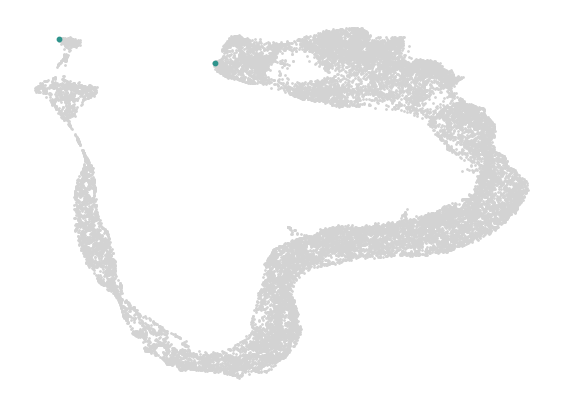

In [23]:
cells=[
        'ATAGACCAGTGTCATC-1-1-0','CGCCATTCACTTCCTG-1-1-0']
palantir.plot.highlight_cells_on_umap(reduced_adata, cells)


In [24]:
reduced_adata.obs

,Sample,Group,n_genes,n_counts,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_rb,pct_counts_rb,...,leiden_S_0.2,leiden_S_0.4,leiden_S_0.6,leiden_S_0.8,leiden_S_1,leiden_S_1.2,leiden_S_1.4,manually_level1,palantir_pseudotime,palantir_entropy
ACACGCGCATAGAGGC-1-0-0,SI-TT-A1,SIX6_D_Cterm,7075.0,88695.0,7064.0,88695,1746.0,1.968544,6467.0,7.291279,...,10,10,10,10,10,10,10,Spermato,0.311542,0.0
TGGGAGACAGTTGGTT-1-0-0,SI-TT-A1,SIX6_D_Cterm,6812.0,70090.0,6807.0,70090,1430.0,2.040234,5066.0,7.227850,...,10,10,10,10,10,10,10,Spermato,0.311352,0.0
CACACAACATGGAGAC-1-0-0,SI-TT-A1,SIX6_D_Cterm,6892.0,68932.0,6885.0,68932,2420.0,3.510706,6916.0,10.033076,...,4,4,4,4,4,4,4,Spermato,0.243845,0.0
GAAATGAAGCCTCCAG-1-0-0,SI-TT-A1,SIX6_D_Cterm,6416.0,58599.0,6410.0,58599,1323.0,2.257718,4214.0,7.191249,...,10,10,10,10,10,10,10,Spermato,0.305372,0.0
TGATTCTAGCCTCTTC-1-0-0,SI-TT-A1,SIX6_D_Cterm,6418.0,57103.0,6407.0,57103,1152.0,2.017407,4287.0,7.507486,...,10,10,10,10,10,10,10,Spermato,0.282486,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AAGCATCTCTGACGCG-1-4-0,SI-TT-H12,RNF212_KO,212.0,319.0,212.0,319,11.0,3.448276,143.0,44.827586,...,8,8,8,8,8,8,8,Spermato,0.003871,0.0
ACATTTCTCGCCAGTG-1-4-0,SI-TT-H12,RNF212_KO,208.0,323.0,208.0,323,15.0,4.643963,159.0,49.226006,...,8,8,8,8,8,8,8,Spermato,0.010305,0.0
GAAACCTCACCTGCAG-1-4-0,SI-TT-H12,RNF212_KO,288.0,373.0,288.0,373,8.0,2.144772,106.0,28.418231,...,8,8,8,8,8,8,8,Spermato,0.007026,0.0
AGTAGTCTCTGGTCAA-1-4-0,SI-TT-H12,RNF212_KO,221.0,328.0,221.0,328,7.0,2.134146,152.0,46.341463,...,8,8,8,8,8,8,8,Spermato,0.011365,0.0


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


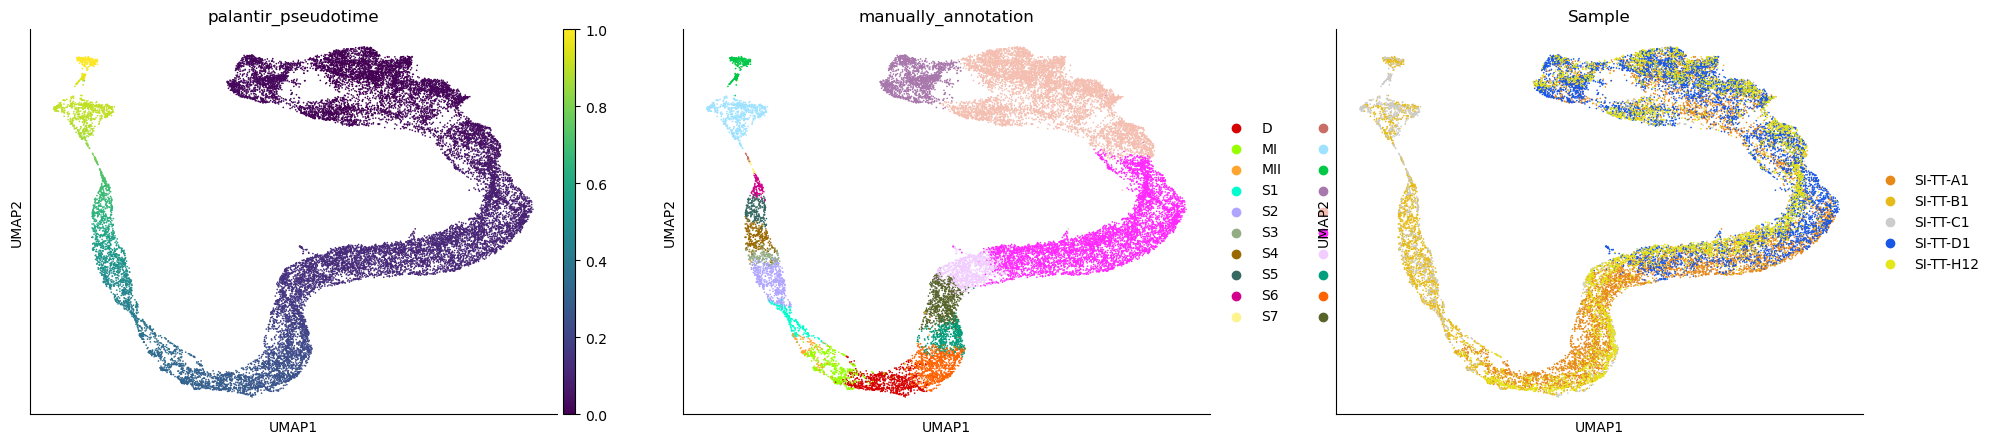

In [25]:
sc.pl.umap(reduced_adata,color=["palantir_pseudotime","manually_annotation","Sample"],cmap="viridis")

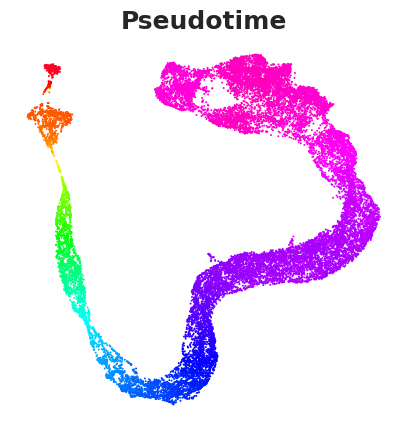

In [60]:
plt.figure(figsize=[5, 5])
plt.rcParams["legend.markerscale"] = 5
sns.set_theme(style="white")
ax = sns.scatterplot(x=reduced_adata.obsm["X_umap"][:,0], y=reduced_adata.obsm["X_umap"][:,1],hue =reduced_adata.obs["palantir_pseudotime"],palette="gist_rainbow_r",marker='.',s=8,linewidth=0)
sns.despine()
plt.axis('off')
ax.get_legend().remove()
#legend = plt.legend(bbox_to_anchor=(1, 1), loc=2, borderaxespad=0., frameon=False)
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2');
plt.title("Pseudotime",weight="bold",size=18,y=1)
plt.savefig("/sas/sara/scRNAseq/CLL_U1_SF3B1/clean_code/figures/UMAP_pseudtime.png", format="png", bbox_inches="tight",dpi=600)

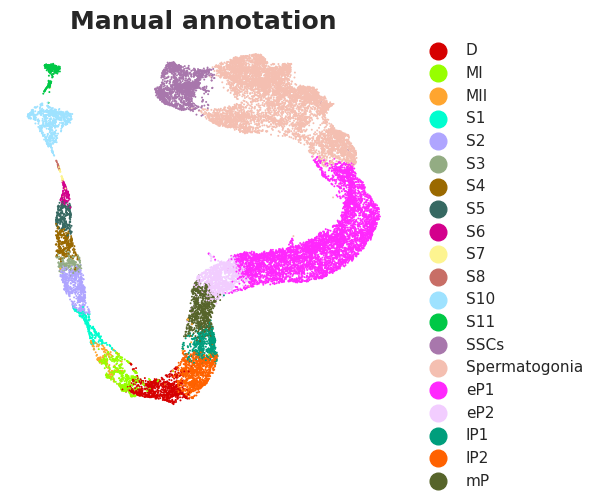

In [70]:
plt.figure(figsize=[5, 5])
plt.rcParams["legend.markerscale"] = 2
sns.set_theme(style="white")
ax = sns.scatterplot(x=reduced_adata.obsm["X_umap"][:,0], y=reduced_adata.obsm["X_umap"][:,1],hue =reduced_adata.obs["manually_annotation"], palette=palette_dict,marker='.',s=8,linewidth=0)
sns.despine()
plt.axis('off')
#ax.get_legend().remove()
#legend = plt.legend(bbox_to_anchor=(1, 1), loc=2, borderaxespad=0., frameon=False)
legend = ax.legend(
    bbox_to_anchor=(1.05, 1),  # shift legend outside to the right
    loc="upper left",
    borderaxespad=0.,
    frameon=False,
    title=None,                # remove legend title
)
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2');
plt.title("Manual annotation",weight="bold",size=18,y=1)
plt.savefig("/sas/sara/scRNAseq/CLL_U1_SF3B1/clean_code/figures/UMAP_manual_annotation.png", format="png", bbox_inches="tight",dpi=600)

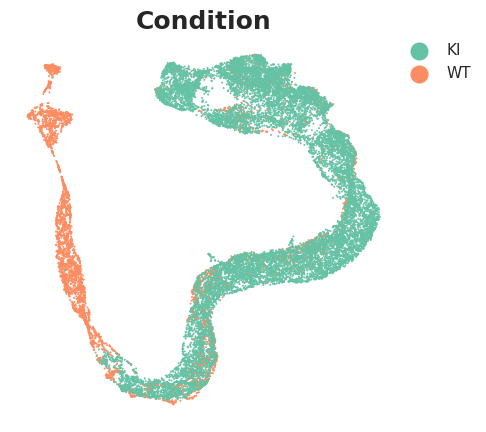

In [69]:
plt.figure(figsize=[5, 5])
plt.rcParams["legend.markerscale"] = 2
sns.set_theme(style="white")
ax = sns.scatterplot(x=reduced_adata.obsm["X_umap"][:,0], y=reduced_adata.obsm["X_umap"][:,1],hue =reduced_adata.obs["Condition"],palette="Set2", marker='.',s=8,linewidth=0)
sns.despine()
plt.axis('off')
ax.get_legend().remove()
legend = plt.legend(bbox_to_anchor=(1, 1), loc=2, borderaxespad=0., frameon=False)
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2');
plt.title("Condition",weight="bold",size=18,y=1)
plt.savefig("/sas/sara/scRNAseq/CLL_U1_SF3B1/clean_code/figures/UMAP_Condition.png", format="png", bbox_inches="tight",dpi=600)

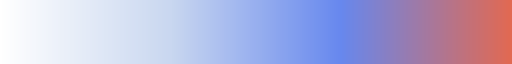

In [27]:
from matplotlib.colors import LinearSegmentedColormap

cs = ["#FFFFFF","#C9D7F0","#6788EE","#E26952"]
red_blue = LinearSegmentedColormap.from_list("cmap_name", cs)
red_blue 

## Cellrank

In [28]:
import cellrank as cr
from cellrank.kernels import PseudotimeKernel

In [29]:
reduced_adata

AnnData object with n_obs × n_vars = 21473 × 5000
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_1', 'l

In [30]:
pk = cr.kernels.PseudotimeKernel(reduced_adata, time_key="palantir_pseudotime",conn_key="neighbors_model")
print(pk)

PseudotimeKernel[n=21473]


In [31]:
pk.compute_transition_matrix()


  0%|          | 0/21473 [00:00<?, ?cell/s]

PseudotimeKernel[n=21473, dnorm=False, scheme='hard', frac_to_keep=0.3]

In [32]:
pk

PseudotimeKernel[n=21473, dnorm=False, scheme='hard', frac_to_keep=0.3]

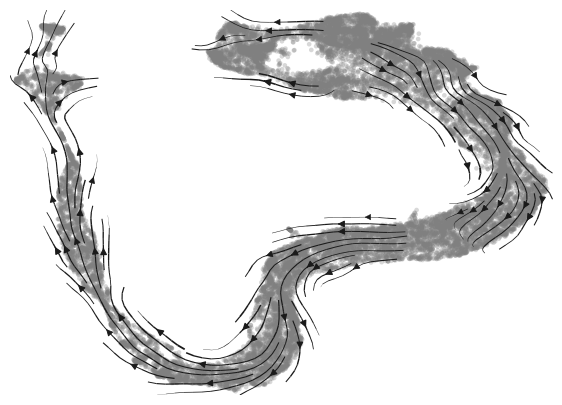

In [33]:
pk.plot_projection(basis="umap", recompute=True)


  0%|          | 0/100 [00:00<?, ?sim/s]

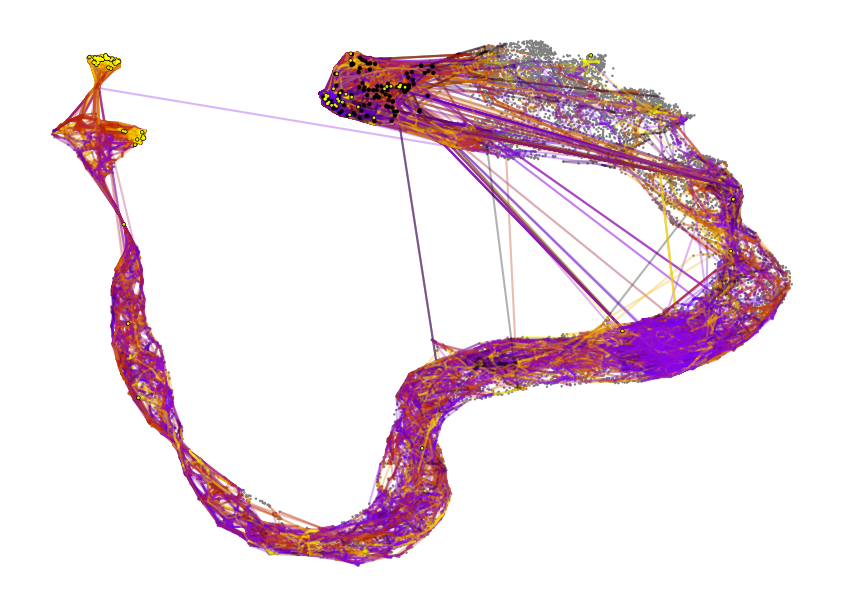

In [34]:
pk.plot_random_walks(
    seed=0,
    n_sims=100,
    start_ixs={"manually_annotation": "SSCs"},
    basis="umap",
    legend_loc="right",
    dpi=150,
)

In [35]:
from cellrank.estimators import GPCCA

g = GPCCA(pk)
print(g)

GPCCA[kernel=PseudotimeKernel[n=21473], initial_states=None, terminal_states=None]


In [36]:
reduced_adata

AnnData object with n_obs × n_vars = 21473 × 5000
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_1', 'l

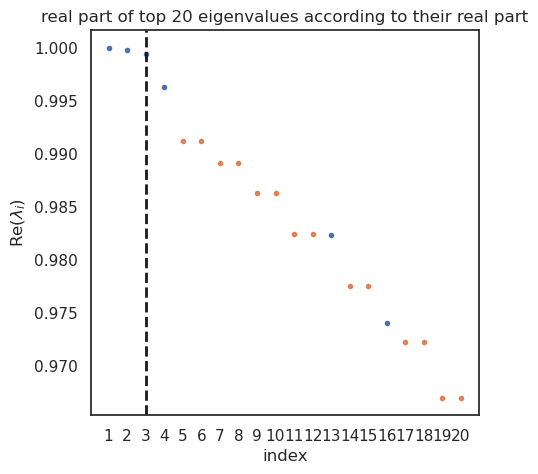

In [37]:
g.compute_schur()
g.plot_spectrum(real_only=True)

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvelo/plotting/utils.py:1391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvelo/plotting/utils.py:1392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


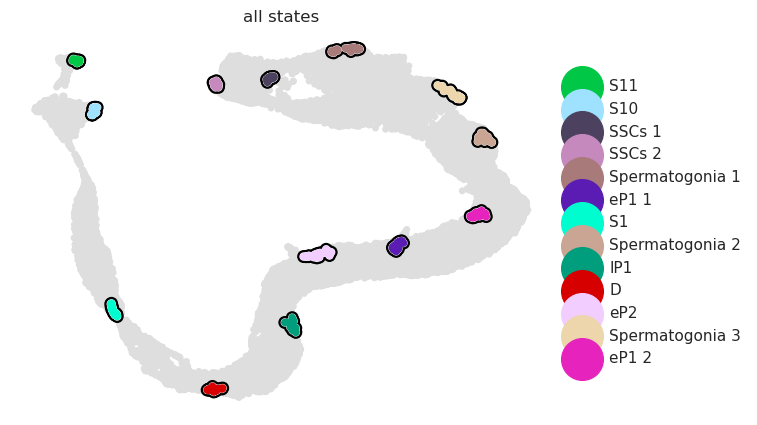

In [38]:
g.compute_macrostates(n_states=13, cluster_key="manually_annotation")
g.plot_macrostates(which="all", legend_loc="right", s=100)

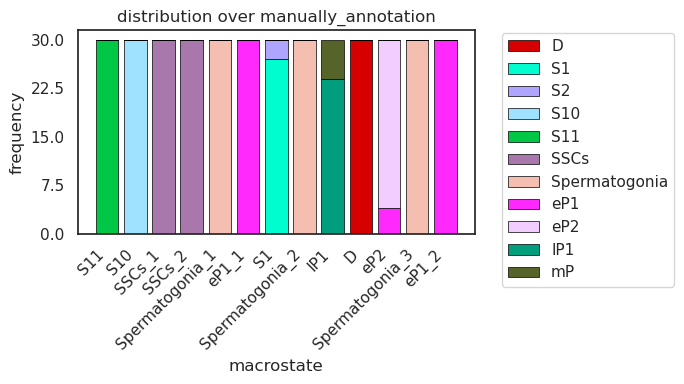

In [39]:
g.plot_macrostate_composition(key="manually_annotation", figsize=(7, 4))


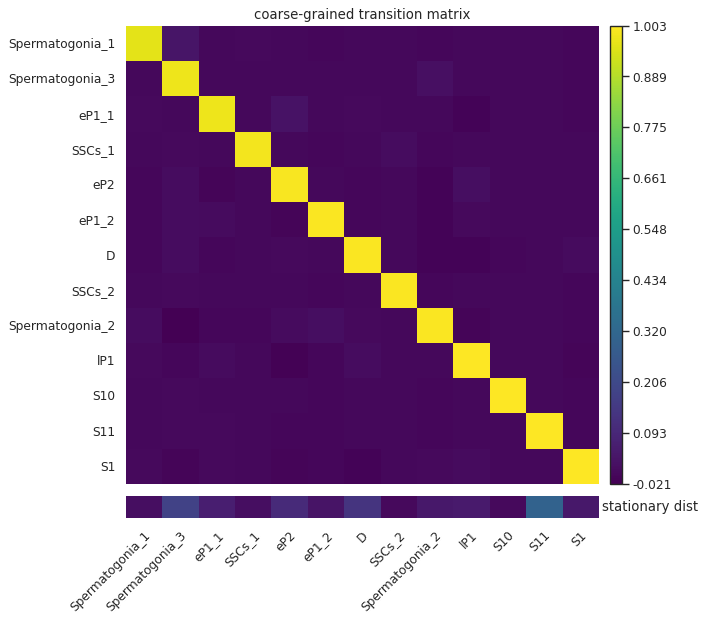

In [40]:
g.plot_coarse_T(annotate=False)


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


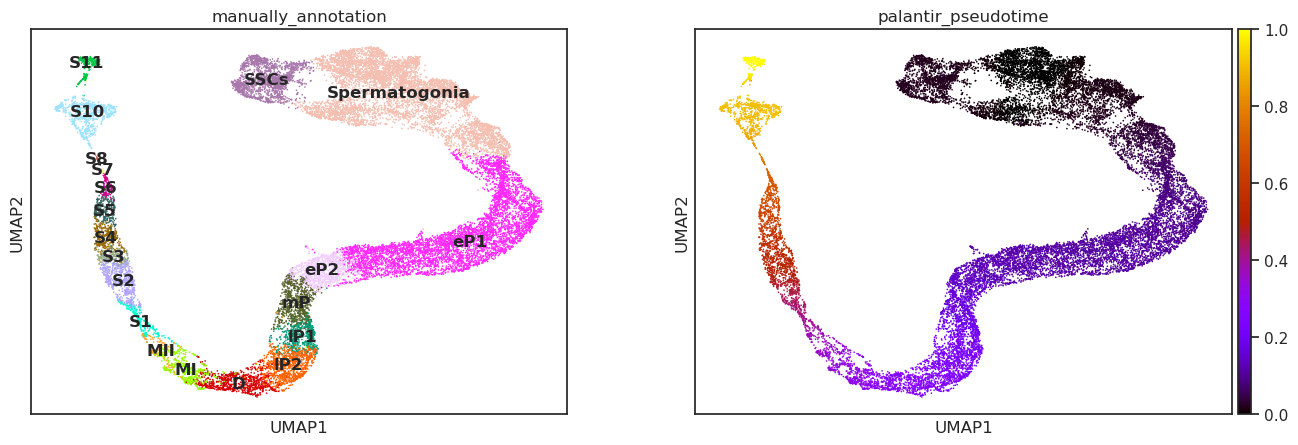

In [41]:
sc.pl.embedding(
    reduced_adata,
    basis="umap",
    color=["manually_annotation", "palantir_pseudotime"],
    color_map="gnuplot",
    legend_loc="on data",
)

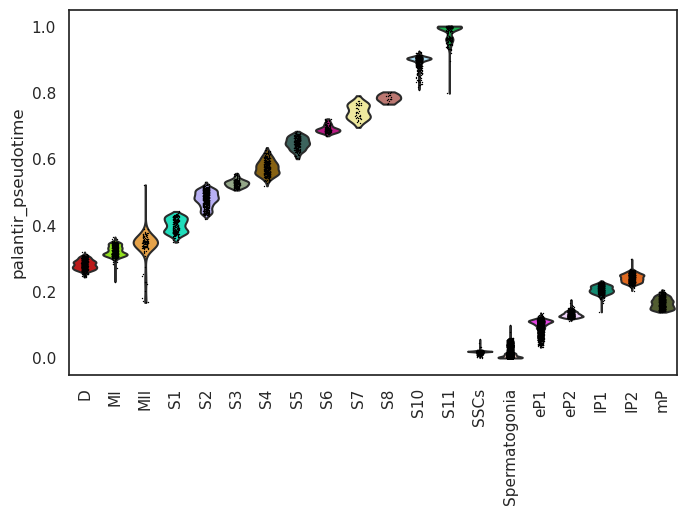

In [42]:
sc.pl.violin(reduced_adata, keys=["palantir_pseudotime"], groupby="manually_annotation", rotation=90)


With this version of GPCCA if i fix the initital and terminal states the algorithm has problems to converge. So leave everything as default first and check if it works.

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvelo/plotting/utils.py:1391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvelo/plotting/utils.py:1392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


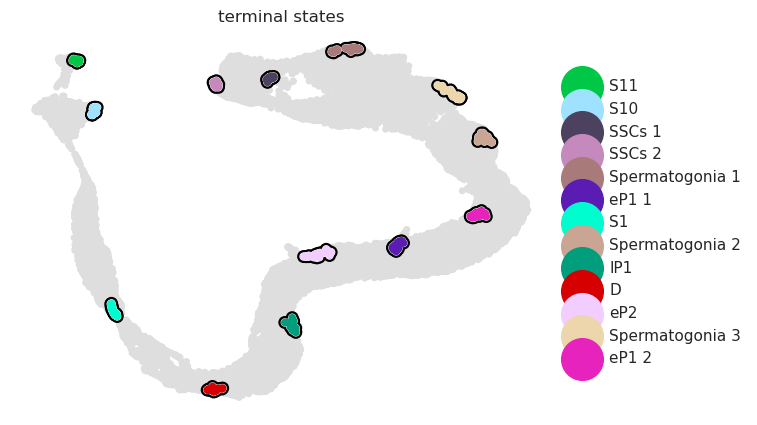

In [43]:
g.predict_terminal_states()
g.plot_macrostates(which="terminal", legend_loc="right", s=100)

In [44]:
g.transition_matrix

<21473x21473 sparse matrix of type '<class 'numpy.float64'>'
	with 270518 stored elements in Compressed Sparse Row format>

In [45]:
g.terminal_states.unique()

[NaN, 'D', 'lP1', 'eP2', 'Spermatogonia_3', ..., 'SSCs_2', 'eP1_2', 'S1', 'S10', 'S11']
Length: 14
Categories (13, object): ['S11', 'S10', 'SSCs_1', 'SSCs_2', ..., 'D', 'eP2', 'Spermatogonia_3', 'eP1_2']

In [46]:
g.compute_fate_probabilities()

Defaulting to `'gmres'` solver.


  0%|          | 0/13 [00:00<?, ?/s]

In [47]:
import pickle

with open("/sas/sara/scRNAseq/pendas/gpcca_estimator.pkl", "wb") as f:
    pickle.dump(g, f)


In [48]:
model = cr.models.GAM(reduced_adata, n_knots=6)


In [78]:
genes_of_interest = ["Kit", 'Tnp1', 'Acr']


In [76]:
reduced_adata

AnnData object with n_obs × n_vars = 21473 × 5000
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_1', 'l

  0%|          | 0/3 [00:00<?, ?gene/s]

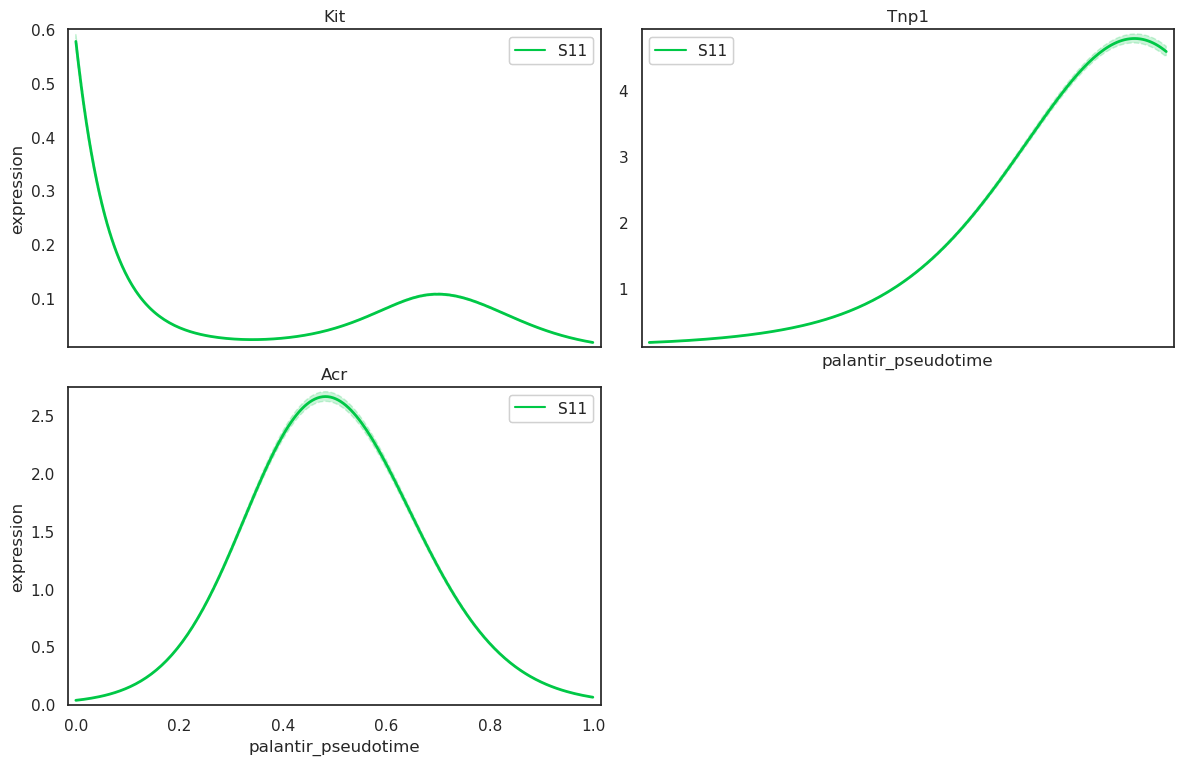

In [79]:
cr.pl.gene_trends(
    reduced_adata,
    model=model,
    lineages="S11",
    data_key="MAGIC_imputed_data",
    genes=genes_of_interest,
    same_plot=True,
    ncols=2,
    time_key="palantir_pseudotime",
    hide_cells=True,
    weight_threshold=(1e-3, 1e-3),
)

In [52]:
reduced_adata

AnnData object with n_obs × n_vars = 21473 × 5000
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_1', 'l

  0%|          | 0/5000 [00:00<?, ?gene/s]

did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge


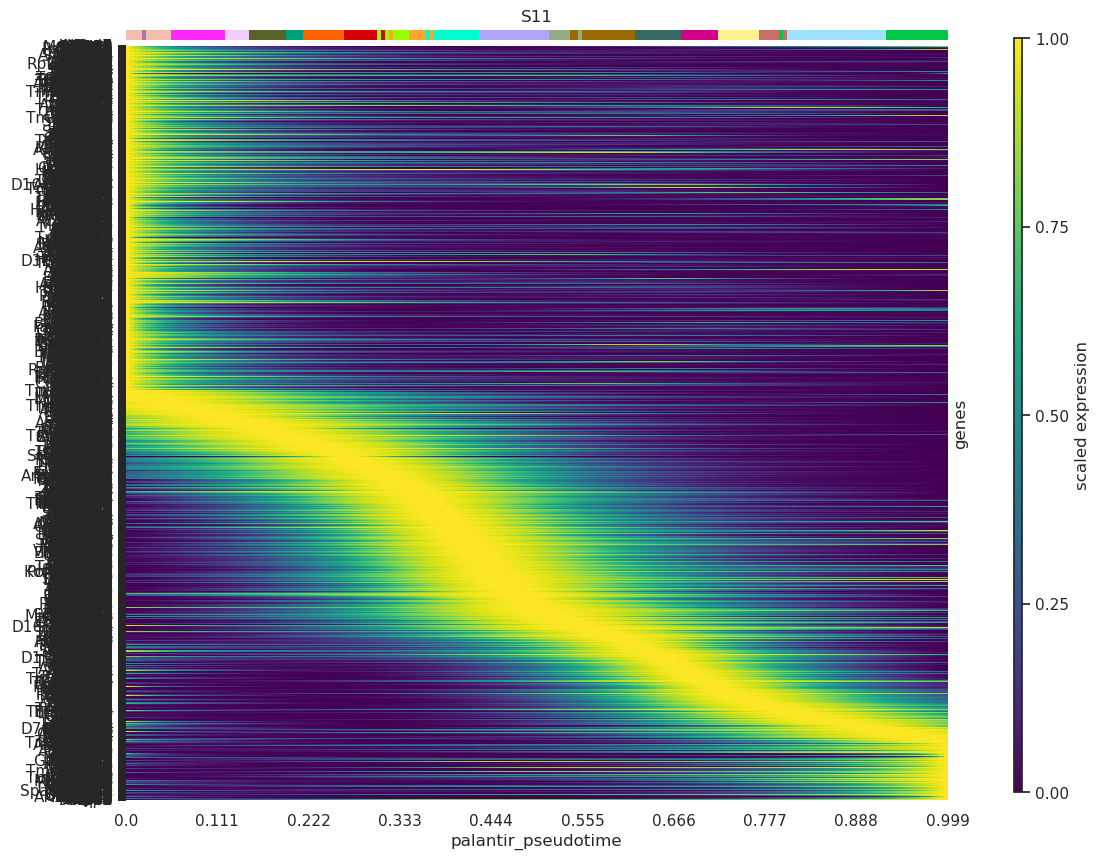

In [53]:
selected_genes = cr.pl.heatmap(
    reduced_adata,
    model=model,
    lineages="S11",
    return_genes=True,
    cluster_key="manually_annotation",
    show_fate_probabilities=False,
    genes=reduced_adata.var_names,
    data_key="MAGIC_imputed_data",
    time_key="palantir_pseudotime",
    figsize=(12, 10),
    show_all_genes=True,
    weight_threshold=(1e-3, 1e-3),n_jobs=50
)



In [54]:
selected_genes

,S11
0,Vamp7
1,Sacs
2,Numbl
3,Blvrb
4,Pld3
...,...
4995,Mbd2
4996,Ptdss2
4997,Nqo2
4998,Ifitm3


  0%|          | 0/5000 [00:00<?, ?gene/s]

did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge
did not converge


AttributeError: 'NoneType' object has no attribute 'set_yticklabels'

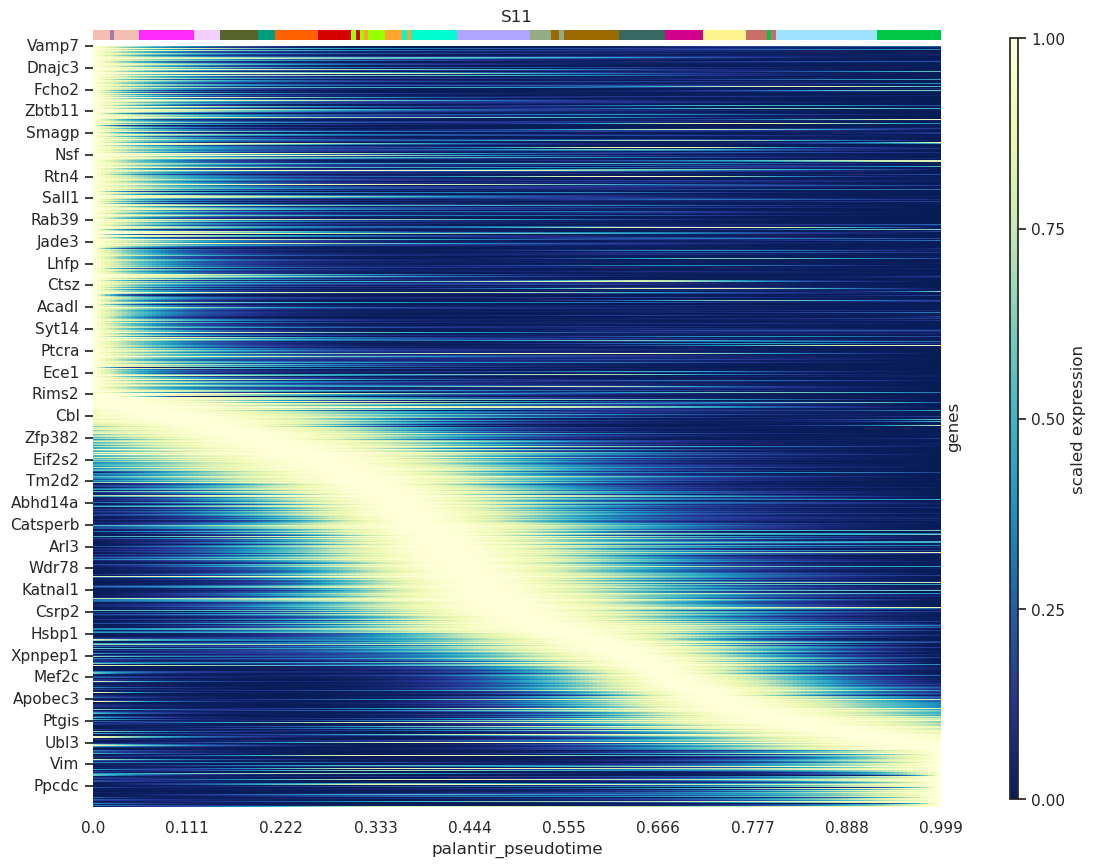

In [55]:
fig, axes = cr.pl.heatmap(
     reduced_adata,
     model=model,
     lineages="S11",
     cluster_key="manually_annotation",
     show_fate_probabilities=False,
     genes=selected_genes["S11"],
     gene_order=selected_genes["S11"],  # Use the genes returned in the previous step
     data_key="MAGIC_imputed_data",
     time_key="palantir_pseudotime",lineage_height=2,
     figsize=(12, 10),
     show_all_genes=False, # Now you can set this to false if you're using a selected list
     weight_threshold=(1e-3, 1e-3),return_figure=True,cmap="YlGnBu_r",n_jobs=70
 )

for ax in np.ravel(axes):
     ax.set_yticklabels([])


clusters = list(legend_info.keys())
colors = list(legend_info.values())
handles = [Patch(color=legend_dict[lab], label=lab) for lab in clusters]

plt.legend(handles=handles, title="manually_annotation", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.savefig(save_dir+'/figures/heatmap_S11_cellrank.png', bbox_inches="tight")

plt.show()

In [56]:
selected_genes.to_csv(save_dir+'/selected_genes.csv')


In [57]:
save_dir='/sas/sara/scRNAseq/pendas/'

reduced_adata.write_h5ad(save_dir+"adata_model_cellrank2.h5ad")